In [1]:
import os
import glob
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv
/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv


In [3]:
BASE_DIR = Path("/kaggle/working/ecommerce_project")

RAW_DIR = BASE_DIR / "raw"
PARQUET_DIR = BASE_DIR / "parquet"
OUTPUT_DIR = BASE_DIR / "outputs"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(BASE_DIR)

/kaggle/working/ecommerce_project


In [4]:
csv_files = glob.glob(
    "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/*.csv"
)

csv_files

['/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv',
 '/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv']

In [5]:
con = duckdb.connect(
    str(BASE_DIR/ "ecommerce.duckdb")
)

print(con.execute("SELECT version()").fetchone())

('v1.3.2',)


In [6]:
sample_file = csv_files[0]

sample = con.execute(f"""
        SELECT * 
        FROM read_csv_auto('{sample_file}')
        LIMIT 10
""").df()

sample

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-11-01 00:00:00,view,1003461,2053013555631882655,electronics.smartphone,xiaomi,489.07,520088904,4d3b30da-a5e4-49df-b1a8-ba5943f1dd33
1,2019-11-01 00:00:00,view,5000088,2053013566100866035,appliances.sewing_machine,janome,293.65,530496790,8e5f4f83-366c-4f70-860e-ca7417414283
2,2019-11-01 00:00:01,view,17302664,2053013553853497655,None,creed,28.31,561587266,755422e7-9040-477b-9bd2-6a6e8fd97387
3,2019-11-01 00:00:01,view,3601530,2053013563810775923,appliances.kitchen.washer,lg,712.87,518085591,3bfb58cd-7892-48cc-8020-2f17e6de6e7f
4,2019-11-01 00:00:01,view,1004775,2053013555631882655,electronics.smartphone,xiaomi,183.27,558856683,313628f1-68b8-460d-84f6-cec7a8796ef2
5,2019-11-01 00:00:01,view,1306894,2053013558920217191,computers.notebook,hp,360.09,520772685,816a59f3-f5ae-4ccd-9b23-82aa8c23d33c
6,2019-11-01 00:00:01,view,1306421,2053013558920217191,computers.notebook,hp,514.56,514028527,df8184cc-3694-4549-8c8c-6b5171877376
7,2019-11-01 00:00:02,view,15900065,2053013558190408249,None,rondell,30.86,518574284,5e6ef132-4d7c-4730-8c7f-85aa4082588f
8,2019-11-01 00:00:02,view,12708937,2053013553559896355,None,michelin,72.72,532364121,0a899268-31eb-46de-898d-09b2da950b24
9,2019-11-01 00:00:02,view,1004258,2053013555631882655,electronics.smartphone,apple,732.07,532647354,d2d3d2c6-631d-489e-9fb5-06f340b85be0


In [7]:
schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{sample_file}')
""").df()

schema

,column_name,column_type,null,key,default,extra
0,event_time,TIMESTAMP,YES,None,None,None
1,event_type,VARCHAR,YES,None,None,None
2,product_id,BIGINT,YES,None,None,None
3,category_id,BIGINT,YES,None,None,None
4,category_code,VARCHAR,YES,None,None,None
5,brand,VARCHAR,YES,None,None,None
6,price,DOUBLE,YES,None,None,None
7,user_id,BIGINT,YES,None,None,None
8,user_session,VARCHAR,YES,None,None,None


In [8]:
for file in csv_files:
    
    result = con.execute(f"""
        SELECT COUNT(*) AS row_count
        FROM read_csv_auto('{file}')
    """).fetchone()[0]
    
    print(
        Path(file).name,
        f"{result:,} rows"
    )

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019-Nov.csv 67,501,979 rows


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019-Oct.csv 42,448,764 rows


In [9]:
event_counts = con.execute(f"""
    select
        event_type,
        count(*) as events
    from read_csv_auto('{sample_file}')
    group by event_type
    order by events DESC
""").df()

event_counts

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type,events
0,view,63556110
1,cart,3028930
2,purchase,916939


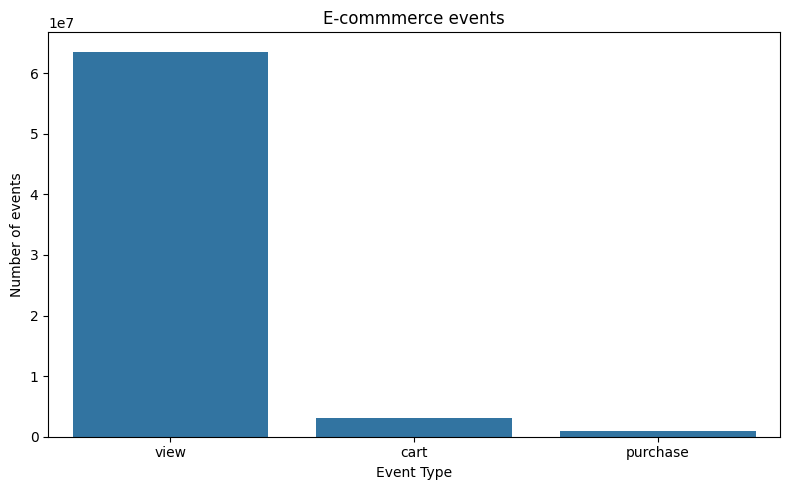

In [10]:
plt.figure(figsize=(8,5))

sns.barplot(
    data = event_counts,
    x = "event_type",
    y = "events"
)

plt.title("E-commmerce events")
plt.xlabel("Event Type")
plt.ylabel("Number of events")

plt.tight_layout()
plt.show()

In [11]:
quality = con.execute(f"""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE event_time IS NULL
        ) AS missing_event_time,

        COUNT(*) FILTER (
            WHERE event_type IS NULL
        ) AS missing_event_type,

        COUNT(*) FILTER (
            WHERE product_id IS NULL
        ) AS missing_product_id,

        COUNT(*) FILTER (
            WHERE category_id IS NULL
        ) AS missing_category_id,

        COUNT(*) FILTER (
            WHERE category_code IS NULL
        ) AS missing_category_code,

        COUNT(*) FILTER (
            WHERE brand IS NULL
        ) AS missing_brand,

        COUNT(*) FILTER (
            WHERE price IS NULL
        ) AS missing_price,

        COUNT(*) FILTER (
            WHERE user_id IS NULL
        ) AS missing_user_id,

        COUNT(*) FILTER (
            WHERE user_session IS NULL
        ) AS missing_session

    FROM read_csv_auto('{sample_file}')
""").df()

quality

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,missing_event_time,missing_event_type,missing_product_id,missing_category_id,missing_category_code,missing_brand,missing_price,missing_user_id,missing_session
0,67501979,0,0,0,0,21898171,9218235,0,0,10


In [12]:
con.execute(f"""
    SELECT DISTINCT event_type
    FROM read_csv_auto('{sample_file}')
    ORDER BY event_type
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,event_type
0,cart
1,purchase
2,view


In [13]:
con.execute(f"""
    SELECT
        MIN(price) AS min_price,
        MAX(price) AS max_price,
        AVG(price) AS avg_price,
        MEDIAN(price) AS median_price
    FROM read_csv_auto('{sample_file}')
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_price,max_price,avg_price,median_price
0,0.0,2574.07,292.459317,165.77


In [14]:
file_pattern = (
    "/kaggle/input/datasets/mkechinov/"
    "ecommerce-behavior-data-from-multi-category-store/"
    "*.csv"
)

con.execute(f"""
    CREATE OR REPLACE VIEW raw_events AS
    SELECT *
    FROM read_csv_auto(
        '{file_pattern}',
        union_by_name = true
    )
""")

In [15]:
con.execute("""
    SELECT COUNT(*) AS total_events
    FROM raw_events
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events
0,109950743


In [16]:
con.execute("""
CREATE OR REPLACE TABLE staging_events AS

SELECT
    CAST(event_time AS TIMESTAMP) AS event_time,

    LOWER(TRIM(event_type)) AS event_type,

    CAST(product_id AS BIGINT) AS product_id,

    CAST(category_id AS BIGINT) AS category_id,

    NULLIF(TRIM(category_code), '') AS category_code,

    NULLIF(LOWER(TRIM(brand)), '') AS brand,

    CAST(price AS DOUBLE) AS price,

    CAST(user_id AS BIGINT) AS user_id,

    NULLIF(TRIM(user_session), '') AS user_session

FROM raw_events
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [17]:
con.execute("""
    SELECT *
    FROM staging_events
    LIMIT 10
""").df()

,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-11-01 00:00:00,view,1003461,2053013555631882655,electronics.smartphone,xiaomi,489.07,520088904,4d3b30da-a5e4-49df-b1a8-ba5943f1dd33
1,2019-11-01 00:00:00,view,5000088,2053013566100866035,appliances.sewing_machine,janome,293.65,530496790,8e5f4f83-366c-4f70-860e-ca7417414283
2,2019-11-01 00:00:01,view,17302664,2053013553853497655,None,creed,28.31,561587266,755422e7-9040-477b-9bd2-6a6e8fd97387
3,2019-11-01 00:00:01,view,3601530,2053013563810775923,appliances.kitchen.washer,lg,712.87,518085591,3bfb58cd-7892-48cc-8020-2f17e6de6e7f
4,2019-11-01 00:00:01,view,1004775,2053013555631882655,electronics.smartphone,xiaomi,183.27,558856683,313628f1-68b8-460d-84f6-cec7a8796ef2
5,2019-11-01 00:00:01,view,1306894,2053013558920217191,computers.notebook,hp,360.09,520772685,816a59f3-f5ae-4ccd-9b23-82aa8c23d33c
6,2019-11-01 00:00:01,view,1306421,2053013558920217191,computers.notebook,hp,514.56,514028527,df8184cc-3694-4549-8c8c-6b5171877376
7,2019-11-01 00:00:02,view,15900065,2053013558190408249,None,rondell,30.86,518574284,5e6ef132-4d7c-4730-8c7f-85aa4082588f
8,2019-11-01 00:00:02,view,12708937,2053013553559896355,None,michelin,72.72,532364121,0a899268-31eb-46de-898d-09b2da950b24
9,2019-11-01 00:00:02,view,1004258,2053013555631882655,electronics.smartphone,apple,732.07,532647354,d2d3d2c6-631d-489e-9fb5-06f340b85be0


In [18]:
con.execute("""
    DESCRIBE staging_events
""").df()

,column_name,column_type,null,key,default,extra
0,event_time,TIMESTAMP,YES,None,None,None
1,event_type,VARCHAR,YES,None,None,None
2,product_id,BIGINT,YES,None,None,None
3,category_id,BIGINT,YES,None,None,None
4,category_code,VARCHAR,YES,None,None,None
5,brand,VARCHAR,YES,None,None,None
6,price,DOUBLE,YES,None,None,None
7,user_id,BIGINT,YES,None,None,None
8,user_session,VARCHAR,YES,None,None,None


In [19]:
con.execute("""
CREATE OR REPLACE TABLE enriched_events AS

SELECT

    event_time,

    CAST(event_time AS DATE) AS event_date,

    EXTRACT(YEAR FROM event_time) AS event_year,

    EXTRACT(MONTH FROM event_time) AS event_month,

    EXTRACT(DAY FROM event_time) AS event_day,

    EXTRACT(HOUR FROM event_time) AS event_hour,

    DAYNAME(event_time) AS day_name,

    event_type,

    product_id,

    category_id,

    category_code,

    brand,

    price,

    user_id,

    user_session

FROM staging_events
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [20]:
kpis = con.execute("""
SELECT

    COUNT(*) AS total_events,

    COUNT(DISTINCT user_id) AS total_users,

    COUNT(DISTINCT user_session) AS total_sessions,

    COUNT(*) FILTER (
        WHERE event_type = 'view'
    ) AS views,

    COUNT(*) FILTER (
        WHERE event_type = 'cart'
    ) AS cart_events,

    COUNT(*) FILTER (
        WHERE event_type = 'purchase'
    ) AS purchase_events,

    COUNT(DISTINCT user_id) FILTER (
        WHERE event_type = 'purchase'
    ) AS purchasing_users,

    SUM(price) FILTER (
        WHERE event_type = 'purchase'
    ) AS revenue

FROM enriched_events
""").df()

kpis

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_events,total_users,total_sessions,views,cart_events,purchase_events,purchasing_users,revenue
0,109950743,5316649,23016650,104335509,3955446,1659788,697470,5.051524e+08


In [21]:
order_metrics = con.execute("""
SELECT

    COUNT(DISTINCT user_session) AS orders,

    SUM(price) AS revenue,

    SUM(price)
        / NULLIF(COUNT(DISTINCT user_session), 0)
        AS average_order_value

FROM enriched_events

WHERE event_type = 'purchase'
""").df()

order_metrics

,orders,revenue,average_order_value
0,1402758,5.051524e+08,360.113714


In [22]:
conversion = con.execute("""
WITH users AS (

    SELECT DISTINCT user_id
    FROM enriched_events
    WHERE user_id IS NOT NULL

),

buyers AS (

    SELECT DISTINCT user_id
    FROM enriched_events
    WHERE event_type = 'purchase'
      AND user_id IS NOT NULL

)

SELECT

    (SELECT COUNT(*) FROM users) AS total_users,

    (SELECT COUNT(*) FROM buyers) AS purchasing_users,

    ROUND(
        100.0
        * (SELECT COUNT(*) FROM buyers)
        / NULLIF(
            (SELECT COUNT(*) FROM users),
            0
        ),
        2
    ) AS conversion_rate_pct

""").df()

conversion

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_users,purchasing_users,conversion_rate_pct
0,5316649,697470,13.12


In [23]:
funnel = con.execute("""
SELECT

    COUNT(DISTINCT user_id)
        FILTER (WHERE event_type = 'view')
        AS viewed_users,

    COUNT(DISTINCT user_id)
        FILTER (WHERE event_type = 'cart')
        AS cart_users,

    COUNT(DISTINCT user_id)
        FILTER (WHERE event_type = 'purchase')
        AS purchasing_users

FROM enriched_events
""").df()

funnel

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,viewed_users,cart_users,purchasing_users
0,5316128,1054133,697470


In [24]:
funnel_rates = con.execute("""
WITH funnel AS (

    SELECT

        COUNT(DISTINCT user_id)
            FILTER (WHERE event_type = 'view')
            AS viewed_users,

        COUNT(DISTINCT user_id)
            FILTER (WHERE event_type = 'cart')
            AS cart_users,

        COUNT(DISTINCT user_id)
            FILTER (WHERE event_type = 'purchase')
            AS purchasing_users

    FROM enriched_events

)

SELECT

    viewed_users,

    cart_users,

    purchasing_users,

    ROUND(
        100.0 * cart_users /
        NULLIF(viewed_users, 0),
        2
    ) AS view_to_cart_pct,

    ROUND(
        100.0 * purchasing_users /
        NULLIF(cart_users, 0),
        2
    ) AS cart_to_purchase_pct,

    ROUND(
        100.0 * purchasing_users /
        NULLIF(viewed_users, 0),
        2
    ) AS view_to_purchase_pct

FROM funnel
""").df()

funnel_rates

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,viewed_users,cart_users,purchasing_users,view_to_cart_pct,cart_to_purchase_pct,view_to_purchase_pct
0,5316128,1054133,697470,19.83,66.17,13.12


In [25]:
monthly_revenue = con.execute("""
SELECT

    DATE_TRUNC('month', event_time) AS month,

    COUNT(DISTINCT user_id) AS users,

    COUNT(DISTINCT user_session) AS sessions,

    COUNT(*) FILTER (
        WHERE event_type = 'purchase'
    ) AS purchase_events,

    SUM(price) FILTER (
        WHERE event_type = 'purchase'
    ) AS revenue

FROM enriched_events

GROUP BY 1

ORDER BY 1
""").df()

monthly_revenue

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,users,sessions,purchase_events,revenue
0,2019-10-01,3022290,9244421,742849,2.299575e+08
1,2019-11-01,3696117,13776050,916939,2.751949e+08


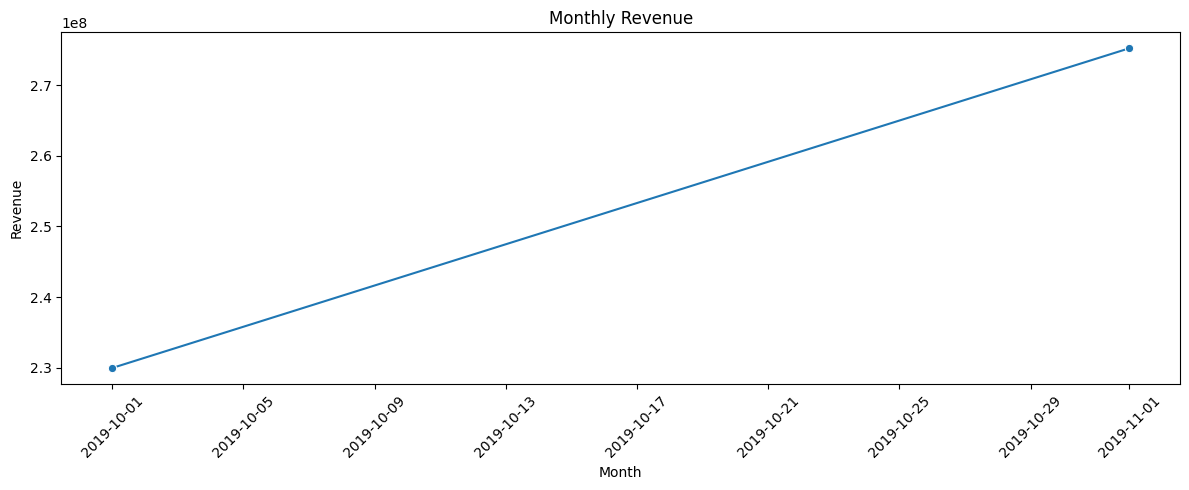

In [26]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
category_revenue = con.execute("""
SELECT

    COALESCE(category_code, 'Unknown') AS category,

    COUNT(DISTINCT user_id) AS users,

    COUNT(DISTINCT user_session) AS sessions,

    COUNT(*) AS purchase_events,

    SUM(price) AS revenue

FROM enriched_events

WHERE event_type = 'purchase'

GROUP BY 1

ORDER BY revenue DESC
LIMIT 30
""").df()

category_revenue

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,category,users,sessions,purchase_events,revenue
0,electronics.smartphone,322110,609168,720665,3.348713e+08
1,Unknown,231804,363177,407643,5.280544e+07
2,electronics.video.tv,32584,46381,51839,2.088056e+07
3,computers.notebook,20389,30086,34023,1.965832e+07
4,electronics.clocks,24605,37093,41143,1.137104e+07
5,appliances.kitchen.washer,23074,32288,35920,1.046055e+07
6,electronics.audio.headphone,42128,63825,71337,9.208629e+06
7,appliances.kitchen.refrigerators,16948,22108,24260,8.552734e+06
8,appliances.environment.vacuum,23019,28708,30571,4.478737e+06
9,electronics.tablet,7640,10549,11741,3.131227e+06


In [28]:
brand_revenue = con.execute("""
SELECT

    COALESCE(brand, 'Unknown') AS brand,

    COUNT(DISTINCT user_id) AS customers,

    COUNT(*) AS purchase_events,

    SUM(price) AS revenue

FROM enriched_events

WHERE event_type = 'purchase'

GROUP BY 1

ORDER BY revenue DESC

LIMIT 30
""").df()

brand_revenue

,brand,customers,purchase_events,revenue
0,apple,134457,308937,2.387218e+08
1,samsung,192790,372923,1.012774e+08
2,xiaomi,75323,124908,2.045390e+07
3,Unknown,84230,131487,1.956632e+07
4,huawei,30151,47204,9.664104e+06
5,lg,14902,21606,8.626907e+06
6,acer,8653,13284,6.924026e+06
7,lucente,15341,26137,6.651659e+06
8,sony,11044,17038,6.341083e+06
9,oppo,16555,25971,5.901501e+06


In [29]:
product_performance = con.execute("""
SELECT

    product_id,

    MAX(category_code) AS category_code,

    MAX(brand) AS brand,

    COUNT(*) FILTER (
        WHERE event_type = 'view'
    ) AS views,

    COUNT(*) FILTER (
        WHERE event_type = 'cart'
    ) AS carts,

    COUNT(*) FILTER (
        WHERE event_type = 'purchase'
    ) AS purchases,

    SUM(price) FILTER (
        WHERE event_type = 'purchase'
    ) AS revenue

FROM enriched_events

GROUP BY product_id

ORDER BY revenue DESC

LIMIT 100
""").df()

product_performance.head(20)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_id,category_code,brand,views,carts,purchases,revenue
0,1005115,electronics.smartphone,apple,910725,80923,34787,33032381.67
1,1005105,electronics.smartphone,apple,473651,32659,15776,21684603.37
2,1004249,electronics.smartphone,apple,462353,39673,17971,13545407.54
3,1005135,electronics.smartphone,apple,237065,17610,7502,12654328.77
4,1004767,electronics.smartphone,samsung,861675,102217,44419,11004748.49
5,1002544,electronics.smartphone,apple,409169,43790,22227,10458895.98
6,1004856,electronics.smartphone,samsung,942167,133328,61265,7917932.74
7,1005116,electronics.smartphone,apple,214874,22001,7036,7161938.29
8,1002524,electronics.smartphone,apple,248725,27446,12877,6965532.89
9,1004870,electronics.smartphone,samsung,462532,54036,21288,6057424.03


In [30]:
product_conversion = con.execute("""
WITH product_metrics AS (

    SELECT

        product_id,

        MAX(category_code) AS category_code,

        MAX(brand) AS brand,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS carts,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchases

    FROM enriched_events

    GROUP BY product_id

)

SELECT

    *,

    ROUND(
        100.0 * purchases /
        NULLIF(views, 0),
        2
    ) AS view_to_purchase_pct,

    ROUND(
        100.0 * carts /
        NULLIF(views, 0),
        2
    ) AS view_to_cart_pct

FROM product_metrics

WHERE views >= 100

ORDER BY view_to_purchase_pct ASC

LIMIT 100
""").df()

product_conversion.head(20)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_id,category_code,brand,views,carts,purchases,view_to_purchase_pct,view_to_cart_pct
0,26203026,None,None,120,0,0,0.0,0.00
1,25509743,None,gerat,263,1,0,0.0,0.38
2,4100233,None,sony,346,0,0,0.0,0.00
3,31501156,None,None,1007,2,0,0.0,0.20
4,4501813,appliances.kitchen.hob,electrolux,117,0,0,0.0,0.00
5,42700017,auto.accessories.winch,t-max,877,0,0,0.0,0.00
6,23200974,None,gelflex,159,8,0,0.0,5.03
7,7100038,furniture.bedroom.bed,None,212,0,0,0.0,0.00
8,18001447,None,samsung,233,7,0,0.0,3.00
9,52800017,sport.bicycle,peruzzo,247,0,0,0.0,0.00


In [31]:
customer_360 = con.execute("""
SELECT

    user_id,

    MIN(event_time) AS first_seen,

    MAX(event_time) AS last_seen,

    COUNT(*) AS total_events,

    COUNT(DISTINCT user_session) AS total_sessions,

    COUNT(*) FILTER (
        WHERE event_type = 'view'
    ) AS views,

    COUNT(*) FILTER (
        WHERE event_type = 'cart'
    ) AS cart_events,

    COUNT(*) FILTER (
        WHERE event_type = 'purchase'
    ) AS purchases,

    SUM(price) FILTER (
        WHERE event_type = 'purchase'
    ) AS revenue

FROM enriched_events

WHERE user_id IS NOT NULL

GROUP BY user_id
""").df()

customer_360.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,user_id,first_seen,last_seen,total_events,total_sessions,views,cart_events,purchases,revenue
0,566175330,2019-10-31 15:57:22,2019-11-12 04:02:07,176,8,175,1,0,NaN
1,548719875,2019-10-09 15:42:21,2019-11-01 00:27:47,41,6,37,1,3,636.54
2,566281189,2019-11-01 00:03:03,2019-11-01 00:03:25,3,1,3,0,0,NaN
3,553524478,2019-10-23 19:48:46,2019-11-27 13:46:45,25,7,25,0,0,NaN
4,561121118,2019-10-17 15:21:11,2019-11-27 11:08:04,347,49,334,10,3,463.34


In [32]:
top_customers = customer_360.sort_values(
    "revenue",
    ascending=False
)

top_customers.head(20)

,user_id,first_seen,last_seen,total_events,total_sessions,views,cart_events,purchases,revenue
1433720,512386086,2019-10-01 04:53:29,2019-11-30 12:10:26,2456,439,1332,534,590,344153.29
1629212,515384420,2019-10-01 02:20:24,2019-11-29 13:30:37,784,132,383,219,182,303144.24
4741802,513117637,2019-10-01 08:36:34,2019-11-27 13:24:53,1154,161,851,91,212,266331.24
1335818,519267944,2019-10-01 07:43:06,2019-11-21 14:15:54,765,178,394,188,183,265569.52
3388114,518514099,2019-10-09 08:14:18,2019-11-28 12:05:41,869,61,447,220,202,203986.07
359878,530834332,2019-10-01 03:03:27,2019-11-27 04:43:50,840,103,590,74,176,188820.87
3797771,549109608,2019-10-02 04:10:06,2019-11-30 11:25:24,1754,210,905,473,376,184394.52
23015,534545940,2019-10-01 04:14:37,2019-11-30 11:34:11,784,103,524,82,178,183309.03
2355478,532499743,2019-10-09 10:17:10,2019-11-30 20:32:42,700,90,355,193,152,180755.40
2065399,515715331,2019-10-01 17:43:51,2019-11-28 06:30:49,845,118,559,161,125,175747.26


In [33]:
rfm = con.execute("""
WITH purchase_data AS (

    SELECT
        user_id,
        event_time,
        user_session,
        price
    FROM enriched_events
    WHERE event_type = 'purchase'
      AND user_id IS NOT NULL

),

reference_date AS (

    SELECT
        MAX(event_time) AS max_date
    FROM purchase_data

)

SELECT

    p.user_id,

    DATE_DIFF(
        'day',
        MAX(p.event_time),
        r.max_date
    ) AS recency_days,

    COUNT(DISTINCT p.user_session)
        AS frequency,

    SUM(p.price)
        AS monetary

FROM purchase_data p

CROSS JOIN reference_date r

GROUP BY
    p.user_id,
    r.max_date
""").df()

rfm.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,user_id,recency_days,frequency,monetary
0,517493752,2,10,1021.15
1,512753572,29,3,64.23
2,557227598,29,1,362.29
3,554981491,29,1,229.90
4,543070768,29,1,74.39


In [34]:
rfm["R_score"] = pd.qcut(
    rfm["recency_days"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm.head()

,user_id,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score
0,517493752,2,10,1021.15,5,5,5,555
1,512753572,29,3,64.23,2,5,1,251
2,557227598,29,1,362.29,2,1,3,213
3,554981491,29,1,229.90,2,1,3,213
4,543070768,29,1,74.39,2,1,1,211


In [35]:
def rfm_segment(row):

    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 4 and f >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "Recent Customers"

    elif r <= 2 and f >= 3 and m >= 3:
        return "At Risk High Value"

    elif r <= 2 and f <= 2:
        return "Inactive"

    else:
        return "Potential"

rfm["segment"] = rfm.apply(
    rfm_segment,
    axis=1
)

rfm["segment"].value_counts()

segment
Potential             175170
Inactive              125885
Recent Customers      105133
Loyal Customers        98758
Champions              98719
At Risk High Value     93805
Name: count, dtype: int64

In [36]:
cohort = con.execute("""
WITH purchases AS (

    SELECT
        user_id,
        event_time
    FROM enriched_events
    WHERE event_type = 'purchase'
      AND user_id IS NOT NULL

),

first_purchase AS (

    SELECT

        user_id,

        DATE_TRUNC(
            'month',
            MIN(event_time)
        ) AS cohort_month

    FROM purchases

    GROUP BY user_id

),

activity AS (

    SELECT

        p.user_id,

        DATE_TRUNC(
            'month',
            p.event_time
        ) AS activity_month,

        fp.cohort_month

    FROM purchases p

    JOIN first_purchase fp
        ON p.user_id = fp.user_id

)

SELECT

    cohort_month,

    activity_month,

    COUNT(DISTINCT user_id) AS active_customers

FROM activity

GROUP BY
    cohort_month,
    activity_month

ORDER BY
    cohort_month,
    activity_month
""").df()

cohort.head()

,cohort_month,activity_month,active_customers
0,2019-10-01,2019-10-01,347118
1,2019-10-01,2019-11-01,91286
2,2019-11-01,2019-11-01,350352


In [37]:
cohort["cohort_period"] = (
    (
        cohort["activity_month"].dt.year
        - cohort["cohort_month"].dt.year
    ) * 12
    +
    (
        cohort["activity_month"].dt.month
        - cohort["cohort_month"].dt.month
    )
)

cohort_pivot = cohort.pivot_table(
    index="cohort_month",
    columns="cohort_period",
    values="active_customers"
)

cohort_pivot

cohort_period,0,1
cohort_month,,
2019-10-01,347118.0,91286.0
2019-11-01,350352.0,NaN


In [38]:
cohort_size = cohort_pivot.iloc[:, 0]

retention = cohort_pivot.divide(
    cohort_size,
    axis=0
) * 100

retention.round(2)

cohort_period,0,1
cohort_month,,
2019-10-01,100.0,26.3
2019-11-01,100.0,NaN


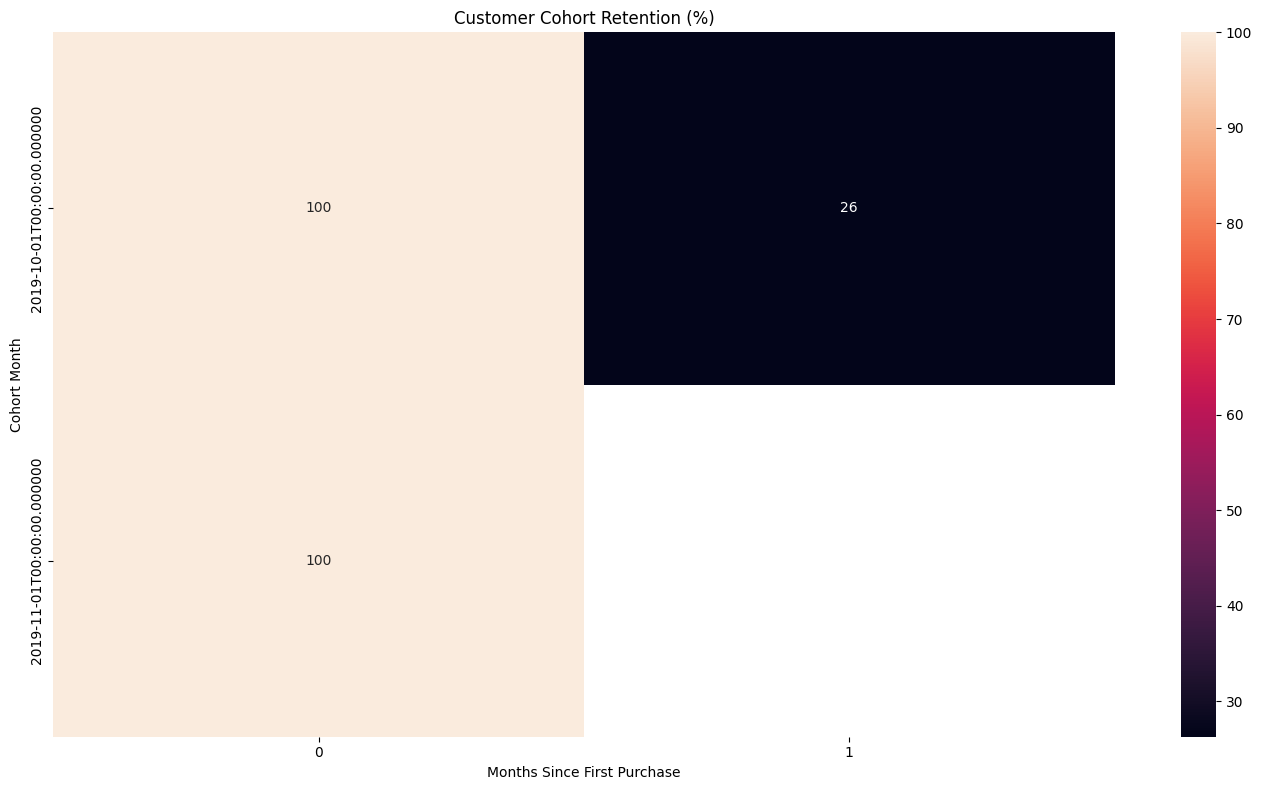

In [39]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt=".0f"
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")

plt.tight_layout()
plt.show()

In [40]:
con.execute("""
CREATE OR REPLACE TABLE dim_product AS

SELECT

    ROW_NUMBER() OVER (
        ORDER BY product_id
    ) AS product_key,

    product_id,

    MAX(category_id) AS category_id,

    MAX(category_code) AS category_code,

    MAX(brand) AS brand

FROM enriched_events

GROUP BY product_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [41]:
con.execute("""
SELECT *
FROM dim_product
LIMIT 10
""").df()

,product_key,product_id,category_id,category_code,brand
0,1,1000365,2053013555631882655,electronics.smartphone,sony
1,2,1000978,2053013555631882655,electronics.smartphone,samsung
2,3,1001588,2053013555631882655,electronics.smartphone,meizu
3,4,1001606,2053013555631882655,electronics.smartphone,apple
4,5,1001618,2053013555631882655,electronics.smartphone,apple
5,6,1001619,2053013555631882655,electronics.smartphone,apple
6,7,1001894,2053013555631882655,electronics.smartphone,honor
7,8,1002042,2053013555631882655,electronics.smartphone,samsung
8,9,1002062,2053013555631882655,electronics.smartphone,samsung
9,10,1002098,2053013555631882655,electronics.smartphone,samsung


In [42]:
con.execute("""
CREATE OR REPLACE TABLE dim_user AS

SELECT

    ROW_NUMBER() OVER (
        ORDER BY user_id
    ) AS user_key,

    user_id,

    MIN(event_time) AS first_seen,

    MAX(event_time) AS last_seen

FROM enriched_events

WHERE user_id IS NOT NULL

GROUP BY user_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [43]:
con.execute("""
CREATE OR REPLACE TABLE dim_category AS

SELECT

    ROW_NUMBER() OVER (
        ORDER BY category_id
    ) AS category_key,

    category_id,

    MAX(category_code) AS category_code

FROM enriched_events

WHERE category_id IS NOT NULL

GROUP BY category_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [44]:
con.execute("""
CREATE OR REPLACE TABLE dim_date AS

WITH dates AS (

    SELECT
        CAST(
            MIN(event_time)
            AS DATE
        ) AS min_date,

        CAST(
            MAX(event_time)
            AS DATE
        ) AS max_date

    FROM enriched_events

)

SELECT

    ROW_NUMBER() OVER (
        ORDER BY d
    ) AS date_key,

    d AS full_date,

    EXTRACT(YEAR FROM d) AS year,

    EXTRACT(QUARTER FROM d) AS quarter,

    EXTRACT(MONTH FROM d) AS month,

    MONTHNAME(d) AS month_name,

    EXTRACT(DAY FROM d) AS day,

    DAYNAME(d) AS day_name,

    EXTRACT(DOW FROM d) AS day_of_week

FROM dates,

LATERAL generate_series(
    min_date,
    max_date,
    INTERVAL '1 day'
) AS t(d)
""")

In [47]:
con.execute("""
CREATE OR REPLACE TABLE fact_event AS
SELECT
    e.event_time,
    dd.date_key,
    du.user_key,
    dp.product_key,
    dc.category_key,
    e.event_type,
    e.product_id,
    e.category_id,
    e.brand,
    e.price,
    e.user_session
FROM enriched_events e

LEFT JOIN dim_date dd
    ON CAST(e.event_time AS DATE) = dd.full_date

LEFT JOIN dim_user du
    ON e.user_id = du.user_id

LEFT JOIN dim_product dp
    ON e.product_id = dp.product_id

LEFT JOIN dim_category dc
    ON e.category_id = dc.category_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [48]:
tables = con.execute("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'main'
ORDER BY table_name
""").df()

tables

,table_name
0,dim_category
1,dim_date
2,dim_product
3,dim_user
4,enriched_events
5,fact_event
6,raw_events
7,staging_events


In [49]:
con.execute("""
SELECT COUNT(*) AS fact_rows
FROM fact_event
""").df()

,fact_rows
0,109950743


In [50]:
con.execute("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT product_id) AS unique_products
FROM dim_product
""").df()

,rows,unique_products
0,206876,206876


In [51]:
con.execute("""
SELECT COUNT(*) AS orphan_products
FROM fact_event
WHERE product_key IS NULL
""").df()

,orphan_products
0,0


In [53]:
con.execute("""
SELECT COUNT(*) AS orphan_users
FROM fact_event
WHERE user_key IS NULL
""").df()

,orphan_users
0,0


In [54]:
con.execute(f"""
COPY dim_date
TO '{OUTPUT_DIR / "dim_date.parquet"}'
(FORMAT PARQUET)
""")

con.execute(f"""
COPY dim_product
TO '{OUTPUT_DIR / "dim_product.parquet"}'
(FORMAT PARQUET)
""")

con.execute(f"""
COPY dim_user
TO '{OUTPUT_DIR / "dim_user.parquet"}'
(FORMAT PARQUET)
""")

con.execute(f"""
COPY dim_category
TO '{OUTPUT_DIR / "dim_category.parquet"}'
(FORMAT PARQUET)
""")

In [55]:
con.execute(f"""
COPY (

    SELECT

        DATE_TRUNC(
            'month',
            event_time
        ) AS month,

        COUNT(*) AS total_events,

        COUNT(DISTINCT user_id) AS users,

        COUNT(DISTINCT user_session) AS sessions,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS carts,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchases,

        SUM(price) FILTER (
            WHERE event_type = 'purchase'
        ) AS revenue

    FROM enriched_events

    GROUP BY 1

    ORDER BY 1

)

TO '{OUTPUT_DIR / "monthly_kpis.parquet"}'
(FORMAT PARQUET)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [56]:
con.execute(f"""
COPY (

    SELECT

        DATE_TRUNC(
            'month',
            event_time
        ) AS month,

        COUNT(*) AS total_events,

        COUNT(DISTINCT user_id) AS users,

        COUNT(DISTINCT user_session) AS sessions,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS carts,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchases,

        SUM(price) FILTER (
            WHERE event_type = 'purchase'
        ) AS revenue

    FROM enriched_events

    GROUP BY 1

    ORDER BY 1

)

TO '{OUTPUT_DIR / "monthly_kpis.parquet"}'
(FORMAT PARQUET)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [57]:
con.execute(f"""
COPY (

    SELECT

        product_id,

        MAX(category_code) AS category_code,

        MAX(brand) AS brand,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS carts,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchases,

        SUM(price) FILTER (
            WHERE event_type = 'purchase'
        ) AS revenue

    FROM enriched_events

    GROUP BY product_id

)

TO '{OUTPUT_DIR / "product_performance.parquet"}'
(FORMAT PARQUET)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [58]:
con.execute(f"""
COPY (

    SELECT

        user_id,

        MIN(event_time) AS first_seen,

        MAX(event_time) AS last_seen,

        COUNT(*) AS total_events,

        COUNT(DISTINCT user_session)
            AS sessions,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS views,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS carts,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchases,

        SUM(price) FILTER (
            WHERE event_type = 'purchase'
        ) AS revenue

    FROM enriched_events

    WHERE user_id IS NOT NULL

    GROUP BY user_id

)

TO '{OUTPUT_DIR / "customer_360.parquet"}'
(FORMAT PARQUET)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))